# Preprocessing

YT Link: (https://www.youtube.com/watch?v=fSt0HV9Ja5c&t=1149s)

dataset: https://drive.google.com/file/d/1F3Yj06z07zPvxqwSO_umqoYKrbnV9FQ8/view?usp=drive_link

In [ ]:
import pandas as pd
import numpy as np

In [ ]:
df = pd.read_csv('/content/data.csv')
df.head()

,customer_id,name,age,gender,email,join_date,last_purchase,total_spent,purchase_count,country,city,postal_code,subscription_type,credit_score,is_active,payment_method,preferred_category,avg_session_duration,device_type,campaign_response
0,4d623250-b704-4df8-aea2-5403458a1d6e,Sean Nelson,41,F,tylersmith@example.org,"Dec 19, 2020",2025-04-02,238.517142,51.0,Germany,Port Michaelmouth,06803,Corporate,663,True,NaN,Groceries,1066.626690,TABLET,NaN
1,e5593c2b-1ed8-4fe8-be82-acced82f9711,Eddie Wood,38,Female,xreed@example.net,30/10/2021,2024-12-25,93.126377,31.0,USA,Brig...,64245,NaN,656,N,PayPal,Clothing,327.762945,mobile,no
2,7240c499-1c3d-4188-8b12-76c515aff931,Abigail Graham,11,M,cartersara@example.com,"May 03, 2022",2025-05-10,873.017713,87.0,Germany,Port Kevinton,43574,Trial,672,N,Cryptocurrency,Clothing,95.654242,Mobile,No
3,43c7001d-4c6d-4011-aa02-e9b57c0e3944,Jessica Contreras,40,NaN,fsalazar@example.org,"Aug 03, 2021",NaN,401.703726,NaN,India,Gillespietown,NaN,Trial,614,True,PayPal,Home,498.371991,mobile,NaN
4,4fb0f886-7e67-4982-bfe0-959272cece1b,Kelly Olson,20,Female,robert21@example.org,"Apr 05, 2024",2025-05-07,1198.186419,34.0,Germany,jamesberg,82358,Premium,692,N,Bank Transfer,Groceries,NaN,mobile,YES


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   customer_id           10000 non-null  object 
 1   name                  9041 non-null   object 
 2   age                   10000 non-null  int64  
 3   gender                8620 non-null   object 
 4   email                 10000 non-null  object 
 5   join_date             10000 non-null  object 
 6   last_purchase         8470 non-null   object 
 7   total_spent           10000 non-null  float64
 8   purchase_count        9059 non-null   float64
 9   country               8433 non-null   object 
 10  city                  10000 non-null  object 
 11  postal_code           7523 non-null   object 
 12  subscription_type     7963 non-null   object 
 13  credit_score          10000 non-null  int64  
 14  is_active             10000 non-null  object 
 15  payment_method      

Ques. Tell the number of columns that are having numerical datatype

In [ ]:
len(df.select_dtypes(['float','int']).columns.tolist())

5

In [ ]:
df.select_dtypes(exclude=object).shape[1]

5

Ques. Tell me the Names and number of unique countries in the country column

In [ ]:
df['country'].unique()

array(['Germany', 'USA', 'India', nan, 'Canada', 'Australia', 'China',
       'France', 'Brazil', 'UK', 'Japan'], dtype=object)

In [ ]:
df['country'].nunique()

10

Ques. Number of missing values in the dataset and accross different columns

In [ ]:
df.isna().sum().sort_values(ascending=False)

,0
postal_code,2477
preferred_category,2125
subscription_type,2037
avg_session_duration,2023
campaign_response,1992
payment_method,1671
country,1567
last_purchase,1530
gender,1380
name,959


In [ ]:
df.isna().sum().sum()

np.int64(18702)

In [ ]:
df.T.isna().sum()

,0
0,2
1,1
2,0
3,5
4,1
...,...
9995,0
9996,2
9997,2
9998,2


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,10000.0,44.716800,14.853035,10.0,35.000000,45.000000,55.000000,99.000000
total_spent,10000.0,502.914509,287.149807,0.0,298.716718,497.856540,699.429102,1772.150969
purchase_count,9059.0,50.394525,29.039124,1.0,25.000000,51.000000,76.000000,100.000000
credit_score,10000.0,695.745000,93.981842,344.0,632.000000,697.000000,766.000000,850.000000
avg_session_duration,7977.0,602.395589,297.331131,0.0,396.683188,593.066471,802.223030,1803.425649


Find the pair with the highest and the lowest correlations

In [ ]:
num_cols = df.select_dtypes('number').columns

In [ ]:
corr_matix = df[num_cols].corr()
corr_matix

,age,total_spent,purchase_count,credit_score,avg_session_duration
age,1.000000,0.001655,-0.001769,0.006844,0.002468
total_spent,0.001655,1.000000,0.004251,-0.006518,-0.009668
purchase_count,-0.001769,0.004251,1.000000,-0.015247,0.019889
credit_score,0.006844,-0.006518,-0.015247,1.000000,-0.009221
avg_session_duration,0.002468,-0.009668,0.019889,-0.009221,1.000000


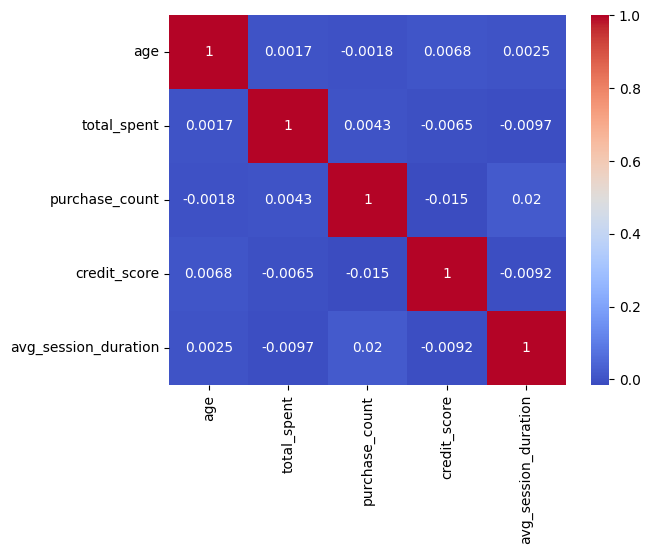

In [ ]:
import seaborn as sns

sns.heatmap(corr_matix, annot=True, cmap='coolwarm');

Ques. For the even indexed rows, odd indexed columns find the number of missing values.



In [ ]:
df.iloc[::2, 1::2].isna().sum().sum()

np.int64(6027)

Ques. Separate out the rows having Country as germany, gender as F, age more than 35 and Device type as mobile. On this separed data, find the most frequent way of payment.

In [ ]:
df.columns

Index(['customer_id', 'name', 'age', 'gender', 'email', 'join_date',
       'last_purchase', 'total_spent', 'purchase_count', 'country', 'city',
       'postal_code', 'subscription_type', 'credit_score', 'is_active',
       'payment_method', 'preferred_category', 'avg_session_duration',
       'device_type', 'campaign_response'],
      dtype='object')

In [ ]:
df.head()

,customer_id,name,age,gender,email,join_date,last_purchase,total_spent,purchase_count,country,city,postal_code,subscription_type,credit_score,is_active,payment_method,preferred_category,avg_session_duration,device_type,campaign_response
0,4d623250-b704-4df8-aea2-5403458a1d6e,Sean Nelson,41,F,tylersmith@example.org,"Dec 19, 2020",2025-04-02,238.517142,51.0,Germany,Port Michaelmouth,06803,Corporate,663,True,NaN,Groceries,1066.626690,TABLET,NaN
1,e5593c2b-1ed8-4fe8-be82-acced82f9711,Eddie Wood,38,Female,xreed@example.net,30/10/2021,2024-12-25,93.126377,31.0,USA,Brig...,64245,NaN,656,N,PayPal,Clothing,327.762945,mobile,no
2,7240c499-1c3d-4188-8b12-76c515aff931,Abigail Graham,11,M,cartersara@example.com,"May 03, 2022",2025-05-10,873.017713,87.0,Germany,Port Kevinton,43574,Trial,672,N,Cryptocurrency,Clothing,95.654242,Mobile,No
3,43c7001d-4c6d-4011-aa02-e9b57c0e3944,Jessica Contreras,40,NaN,fsalazar@example.org,"Aug 03, 2021",NaN,401.703726,NaN,India,Gillespietown,NaN,Trial,614,True,PayPal,Home,498.371991,mobile,NaN
4,4fb0f886-7e67-4982-bfe0-959272cece1b,Kelly Olson,20,Female,robert21@example.org,"Apr 05, 2024",2025-05-07,1198.186419,34.0,Germany,jamesberg,82358,Premium,692,N,Bank Transfer,Groceries,NaN,mobile,YES


In [ ]:
df[(df['country']=='Germany') & (df['gender']=='F') & (df['device_type']=='mobile') & (df['age'] > 35)]['payment_method'].value_counts()

,count
payment_method,
Cryptocurrency,3
PayPal,3
Cash,2
Bank Transfer,2


Ques. Replace ? with np.nan. Drop the customer_id, join_date, last_purchase, email

In [ ]:
df = df.drop(['customer_id', 'join_date', 'last_purchase', 'email'], axis=1)

In [ ]:
df = df.replace({'?': np.nan})

In [ ]:
df.head(2)

,name,age,gender,total_spent,purchase_count,country,city,postal_code,subscription_type,credit_score,is_active,payment_method,preferred_category,avg_session_duration,device_type,campaign_response
0,Sean Nelson,41,F,238.517142,51.0,Germany,Port Michaelmouth,06803,Corporate,663,True,NaN,Groceries,1066.626690,TABLET,NaN
1,Eddie Wood,38,Female,93.126377,31.0,USA,Brig...,64245,NaN,656,N,PayPal,Clothing,327.762945,mobile,no


In [ ]:
nums = df.select_dtypes('number').columns
categories = df.select_dtypes('object').columns

In [ ]:
nums

Index(['age', 'total_spent', 'purchase_count', 'credit_score',
       'avg_session_duration'],
      dtype='object')

In [ ]:
categories

Index(['name', 'gender', 'country', 'city', 'postal_code', 'subscription_type',
       'is_active', 'payment_method', 'preferred_category', 'device_type',
       'campaign_response'],
      dtype='object')

In [ ]:
df.isna().sum().sort_values(ascending=False)

,0
postal_code,2477
preferred_category,2125
subscription_type,2037
avg_session_duration,2023
campaign_response,1992
payment_method,1671
country,1567
gender,1380
name,959
purchase_count,941


## Chaining transformers

Ques.
- Impute missing values in avg_session_duration with mean, purchase count with median value and for remaining by mode value.
- OHE the gender', 'country', 'city'
- Orrdinal encode 'payment_method', 'preferred_category', 'device_type'
- Scale the numericals columns with standard scaler.

In [ ]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [ ]:
impute_ct = ColumnTransformer(transformers=[
    ('mean imputer', SimpleImputer(strategy='mean'), ['avg_session_duration']),
    ('median imputer', SimpleImputer(strategy='median'), ['purchase_count']),
    ('mode imputer', SimpleImputer(strategy='most_frequent'), ['postal_code', 'preferred_category', 'subscription_type'])
], remainder='passthrough', verbose_feature_names_out=False).set_output(transform='pandas')

impute_ct

ColumnTransformer(remainder='passthrough',
                  transformers=[('mean imputer', SimpleImputer(),
                                 ['avg_session_duration']),
                                ('median imputer',
                                 SimpleImputer(strategy='median'),
                                 ['purchase_count']),
                                ('mode imputer',
                                 SimpleImputer(strategy='most_frequent'),
                                 ['postal_code', 'preferred_category',
                                  'subscription_type'])],
                  verbose_feature_names_out=False)

In [ ]:
encode_ct = ColumnTransformer(transformers=[
    ('Ordinal Encoding', OrdinalEncoder(), ['payment_method', 'preferred_category', 'device_type']),
    ('One hot Encoding', OneHotEncoder(sparse_output=False), ['gender', 'country', 'city'])
], remainder='passthrough', verbose_feature_names_out=False).set_output(transform='pandas')

encode_ct

ColumnTransformer(remainder='passthrough',
                  transformers=[('Ordinal Encoding', OrdinalEncoder(),
                                 ['payment_method', 'preferred_category',
                                  'device_type']),
                                ('One hot Encoding',
                                 OneHotEncoder(sparse_output=False),
                                 ['gender', 'country', 'city'])],
                  verbose_feature_names_out=False)

In [ ]:
nums

Index(['age', 'total_spent', 'purchase_count', 'credit_score',
       'avg_session_duration'],
      dtype='object')

In [ ]:
scale_ct = ColumnTransformer(transformers=[
    ('Standard Scaler', StandardScaler(), nums)
], remainder='passthrough', verbose_feature_names_out=False).set_output(transform='pandas')

scale_ct

ColumnTransformer(remainder='passthrough',
                  transformers=[('Standard Scaler', StandardScaler(),
                                 Index(['age', 'total_spent', 'purchase_count', 'credit_score',
       'avg_session_duration'],
      dtype='object'))],
                  verbose_feature_names_out=False)

In [ ]:
pipe = Pipeline(steps=[
    ('imputer', impute_ct),
    ('encoder', encode_ct),
    ('scaler', scale_ct)
]).set_output(transform='pandas')

pipe

Pipeline(steps=[('imputer',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('mean imputer',
                                                  SimpleImputer(),
                                                  ['avg_session_duration']),
                                                 ('median imputer',
                                                  SimpleImputer(strategy='median'),
                                                  ['purchase_count']),
                                                 ('mode imputer',
                                                  SimpleImputer(strategy='most_frequent'),
                                                  ['postal_code',
                                                   'preferred_category',
                                                   'subscription_type'])],
                                   verbose_feature_names_out=...
                                                 ('One hot Encoding',
                                                  OneHotEncoder(sparse_output=False),
                                                  ['gender', 'country',
                                                   'city'])],
                                   verbose_feature_names_out=False)),
                ('scaler',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('Standard Scaler',
                                                  StandardScaler(),
                                                  Index(['age', 'total_spent', 'purchase_count', 'credit_score',
       'avg_session_duration'],
      dtype='object'))],
                                   verbose_feature_names_out=False))])

In [ ]:
df_transformed = pipe.fit_transform(df)

In [ ]:
df_transformed.head()

,age,total_spent,purchase_count,credit_score,avg_session_duration,payment_method,preferred_category,device_type,gender_F,gender_Female,...,city_youngport,city_yvetteville,city_zacharyburgh,city_zacharytown,city_zavalaview,postal_code,subscription_type,name,is_active,campaign_response
0,-0.250251,-0.920811,0.019846,-0.348436,1.748241e+00,NaN,3.0,2.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,06803,Corporate,Sean Nelson,True,NaN
1,-0.452240,-1.427160,-0.703792,-0.422922,-1.034235e+00,4.0,1.0,4.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,64245,Premium,Eddie Wood,N,no
2,-2.270141,1.288950,1.322394,-0.252668,-1.908330e+00,3.0,1.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,43574,Trial,Abigail Graham,N,No
3,-0.317581,-0.352484,0.019846,-0.869839,-3.917409e-01,4.0,4.0,4.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,AB-123,Trial,Jessica Contreras,True,NaN
4,-1.664174,2.421407,-0.595247,-0.039850,-4.281315e-16,0.0,3.0,4.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,82358,Premium,Kelly Olson,N,YES


# Model Building

dataset: https://drive.google.com/file/d/1EuG13JOkmiUwyVhi1V2u1-3KdZYoG3ud/view?usp=drive_link

In [ ]:
df = pd.read_csv('/content/modelBuilding_data.csv')
df.head()

,Marital_Status_Married,Marital_Status_Single,Attrition_Flag_Existing Customer,Gender_M,Education_Level,Income_Category,Card_Category,Customer_Age,Dependent_count,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Total_Revolving_Bal,Total_Trans_Amt,Total_Trans_Ct,Credit_Limit
0,-0.933849,1.07353,0.445200,1.061025,-1.173014,1.335842,2.776225,1.662446,-1.888562,0.505090,-0.509506,-0.357050,0.470792,0.250626,-0.989963,-1.640582,34516.0
1,-0.933849,1.07353,0.445200,1.061025,0.830949,1.335842,-0.248946,0.000000,-0.258442,-0.121281,1.413159,-1.345423,-2.219448,0.171715,-0.884469,-1.172242,13551.0
2,-0.933849,1.07353,0.445200,-0.942484,-1.173014,-0.887731,-0.248946,0.346445,-0.258442,0.129267,0.772271,-1.345423,1.367539,1.491346,-0.287765,-0.022681,2934.0
3,-0.933849,1.07353,0.445200,1.061025,0.830949,1.335842,-0.248946,-0.179955,-0.258442,0.379816,1.413159,0.631324,0.470792,-1.399216,-0.242299,0.019896,1613.0
4,-0.933849,1.07353,-2.246183,1.061025,-1.173014,2.077033,-0.248946,0.083245,0.556618,0.003993,-0.509506,0.631324,1.367539,-1.399216,-0.696662,-1.342548,34516.0


Instructions for data split:
- credit limit is target column
- 30% as test set
- random state = 0
- use train test split

In [ ]:
X = df.drop('Credit_Limit', axis=1)
y = df['Credit_Limit']

In [ ]:
X.head()

,Marital_Status_Married,Marital_Status_Single,Attrition_Flag_Existing Customer,Gender_M,Education_Level,Income_Category,Card_Category,Customer_Age,Dependent_count,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Total_Revolving_Bal,Total_Trans_Amt,Total_Trans_Ct
0,-0.933849,1.07353,0.445200,1.061025,-1.173014,1.335842,2.776225,1.662446,-1.888562,0.505090,-0.509506,-0.357050,0.470792,0.250626,-0.989963,-1.640582
1,-0.933849,1.07353,0.445200,1.061025,0.830949,1.335842,-0.248946,0.000000,-0.258442,-0.121281,1.413159,-1.345423,-2.219448,0.171715,-0.884469,-1.172242
2,-0.933849,1.07353,0.445200,-0.942484,-1.173014,-0.887731,-0.248946,0.346445,-0.258442,0.129267,0.772271,-1.345423,1.367539,1.491346,-0.287765,-0.022681
3,-0.933849,1.07353,0.445200,1.061025,0.830949,1.335842,-0.248946,-0.179955,-0.258442,0.379816,1.413159,0.631324,0.470792,-1.399216,-0.242299,0.019896
4,-0.933849,1.07353,-2.246183,1.061025,-1.173014,2.077033,-0.248946,0.083245,0.556618,0.003993,-0.509506,0.631324,1.367539,-1.399216,-0.696662,-1.342548


In [ ]:
y.head()

,Credit_Limit
0,34516.0
1,13551.0
2,2934.0
3,1613.0
4,34516.0


In [ ]:
# Splitting the data

from sklearn.model_selection import train_test_split

X_train , X_test, y_train , y_test = train_test_split(X, y, test_size=0.3, random_state=0)

Ques. Implement a lasso regressor with the help of a SGD Regressor, keep random state = 0.

In [ ]:
from sklearn.linear_model import SGDRegressor

lasso_sgd = SGDRegressor(penalty='l1', random_state=0)
lasso_sgd.fit(X_train, y_train)
lasso_sgd.score(X_test, y_test)

0.5099033058066137

In [ ]:
from sklearn.metrics import r2_score

y_pred = lasso_sgd.predict(X_test)
r2_score(y_test, y_pred)
r2_score()

0.5099033058066137

In [ ]:
from sklearn.metrics import mean_absolute_error

y_pred = lasso_sgd.predict(X_test)
mean_absolute_error(y_test, y_pred)

4479.486618867076

Ques. implement linear regression model and tell the highest abs coef and the intercept value

In [ ]:
from sklearn.linear_model import LinearRegression

In [ ]:
lr = LinearRegression()
lr.fit(X_train, y_train)

LinearRegression()

In [ ]:
lr.intercept_

np.float64(8613.336555546332)

In [ ]:
lr.coef_

array([-467.26904179,   55.61521711,  338.8221939 , -199.30827746,
         11.84874744, 4439.47223566, 4082.33754683,   14.9550112 ,
        142.09014435,   79.84918725,   31.2559697 ,  -27.29883434,
        289.37543584,   48.20070967, 1267.47545088, -897.87089462])

In [ ]:
abs(lr.coef_).max()

np.float64(4439.472235655139)

In [ ]:
np.argmax(abs(lr.coef_))

np.int64(5)

Ques. Build a Decision tree Regressor  with following parameters:
- min_samples_leaf = 5
- max_depth = 200
- min_samples_split = 6
- splitter = 'best'
- random state = 0


Find the number of values in the right child and the lest child at the first split. also what is the depth of my tree.

In [ ]:
from sklearn.tree import DecisionTreeRegressor

dt = DecisionTreeRegressor(min_samples_split=6, min_samples_leaf=5, max_depth=200, splitter='best', random_state=0)
dt.fit(X_train, y_train)

DecisionTreeRegressor(max_depth=200, min_samples_leaf=5, min_samples_split=6,
                      random_state=0)

In [ ]:
dt.get_depth()

25

In [ ]:
dt.tree_.max_depth

25

In [ ]:
import matplotlib.pyplot as plt

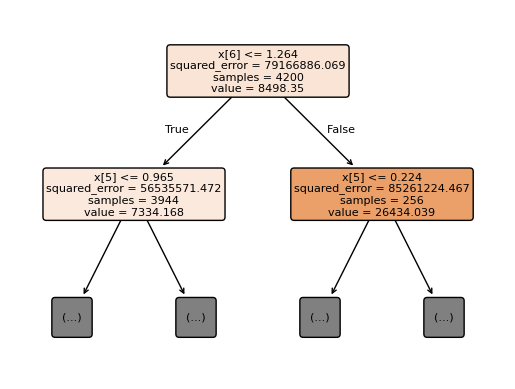

In [ ]:
from sklearn.tree import plot_tree

plot_tree(dt, filled=True, rounded=True, fontsize=8, max_depth=1);
plt.show()



Create a pipeline of the PCA() as transformer and Lasso as an estimator.

- Use GridSearchCV for tuning the hyperparameters of the created pipeline on training dataset.


```
1. Values of n_components for PCA to be [0.9, 0.95]
2. lasso alpha value to be taken as : [10, 1, 0.01, 0.001]
```
-  scoring : neg_mean_absolute_error.
-  Use 5 fold cross validation.
- n_jobs = -1 (negative one) [it helps in using all the computational power to run this job]

(Note: Kindly ignore the warning.)

In [ ]:
from sklearn.decomposition import PCA
from sklearn.linear_model import Lasso

pipe = Pipeline([('pca',PCA()),('estimator',Lasso())])
pipe

Pipeline(steps=[('pca', PCA()), ('estimator', Lasso())])

In [ ]:
import warnings
warnings.filterwarnings('ignore')

In [ ]:
from sklearn.model_selection import GridSearchCV

parm_grid = {
    'pca__n_components': [0.9, 0.95],
    'estimator__alpha': [10, 1, 0.01, 0.001]
}

In [ ]:
grid_lasso = GridSearchCV(pipe, parm_grid, scoring='neg_mean_absolute_error', cv=5, n_jobs=-1)
grid_lasso.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('pca', PCA()), ('estimator', Lasso())]),
             n_jobs=-1,
             param_grid={'estimator__alpha': [10, 1, 0.01, 0.001],
                         'pca__n_components': [0.9, 0.95]},
             scoring='neg_mean_absolute_error')

What is the variance explained by the first principle component on training dataset?

In [ ]:
best_model = grid_lasso.best_estimator_

In [ ]:
pca_comp = best_model.named_steps['pca']

In [ ]:
pca_comp

PCA(n_components=0.9)

In [ ]:
pca_comp.explained_variance_[0]

np.float64(2.3006010459299153)

In [ ]:
pca_comp.explained_variance_

array([2.30060105, 1.86277285, 1.82258779, 1.7563744 , 1.39043076,
       1.02704147, 0.98057531, 0.93375969, 0.92331727, 0.86057551,
       0.8137042 ])